# Session 4 — Ranking: Feature Engineering + LightGBM LambdaRank

**Objective.** Turn retriever candidates into a ranked top-K list, per `project.md`'s Ranking requirements: 10+ features (user, item, cross, temporal), a LightGBM ranker with the `lambdarank` objective, and NDCG@10 / Recall@20 / Recall@50 / Catalog Coverage against a retrieval-only baseline.

**Inputs.** `data/train.parquet`, `val.parquet`, `test.parquet` (time-based split, `label` = `rating >= 4`) and `data/items_meta.parquet`.

**Three retrievers, three rankers.** Rather than picking one retriever, this notebook builds a full retrieval → ranking pipeline for each of the team's three retrievers — Popularity (`notebooks/02_baseliners.ipynb`), MF-BPR (`notebooks/recsys-mf-bpr.ipynb`), and Two-tower (`notebooks/recsys-retrieval-twotower.ipynb`) — and compares all three, retrieval-only vs. +LightGBM, side by side. This directly answers project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

**Graded labels, not binary — this dataset has no impression logs.** Amazon Reviews has no "shown but not clicked" signal. A negative is any candidate the user never interacted with. We use 3 levels instead of 2 since `lambdarank` expects graded relevance: `label=2` (rating≥4), `label=1` (interacted, rating<4), `label=0` (no interaction).

## 0. Setup

In [15]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

t0 = time.time()

REPO_ROOT = Path("..").resolve()
DATA_DIR = REPO_ROOT / "data"
BASELINES_DIR = REPO_ROOT / "data" / "baselines"
CKPT_DIR = REPO_ROOT / "checkpoints" / "lightgbm_ranker"
RESULTS_PATH = REPO_ROOT / "reports" / "ranking_metrics.csv"

SEED = 42
HALFLIFE_DAYS = 90          # recency-decay halflife for affinity features (books: weeks-to-months per class material, we use 90d)
TOP_K_CANDIDATES = 100      # candidates per user, matches project.md's "top-100/user" retrieval spec
POOL_SIZE = 400             # popularity pool size val/test draw non-seen candidates from

print(f"Repo root: {REPO_ROOT}")
print(f"Data dir:  {DATA_DIR}")

Repo root: E:\EPITA\Recommended System\recsys_amazon_book
Data dir:  E:\EPITA\Recommended System\recsys_amazon_book\data


## 1. Load prepared data

In [16]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
val = pd.read_parquet(DATA_DIR / "val.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")
items_meta = pd.read_parquet(DATA_DIR / "items_meta.parquet")

print(f"train={train.shape}  val={val.shape}  test={test.shape}  items_meta={items_meta.shape}  ({time.time()-t0:.1f}s)")
items_meta.head(3)

train=(592954, 6)  val=(18656, 6)  test=(10234, 6)  items_meta=(43014, 8)  (0.2s)


,parent_asin,title,main_category,categories,author,average_rating,price,image_url
0,B003P2WETK,Inspector Imanishi Investigates (Soho Crime),Buy a Kindle,"[Books, Mystery, Thriller & Suspense, Thriller...",Seicho Matsumoto,4.0,9.99,https://m.media-amazon.com/images/I/51UHERs91b...
1,125023655X,Cleo Porter and the Body Electric,Books,"[Books, Children's Books, Science Fiction & Fa...",Jake Burt,4.5,9.59,https://m.media-amazon.com/images/I/51hWlklilj...
2,1401293220,Whistle: A New Gotham City Hero,Books,"[Books, Teen & Young Adult, Literature & Fiction]",E. Lockhart,4.4,10.69,https://m.media-amazon.com/images/I/41yLEyvMOZ...


## 2. Item metadata prep

`categories` is the full path, e.g. `["Books", "Mystery, Thriller & Suspense", "Thrillers & Suspense"]`. `categories[0]` is always "Books", so `categories[1]` is the top-level genre (`item_category`). The full path (capped at 4 levels) also feeds the `category_overlap_affinity` feature below. `average_rating`/`price` are filled with catalog-wide averages instead of 0, since 0 would look like "actively bad" rather than "unknown".

In [17]:
def top_genre(cats):
    if cats is None or len(cats) == 0:
        return None
    return cats[1] if len(cats) > 1 else cats[0]


items_meta = items_meta.copy()
items_meta["item_category"] = items_meta["categories"].apply(top_genre)
items_meta["categories_capped"] = items_meta["categories"].apply(lambda c: list(c[:4]) if c is not None else [])

price_median = items_meta["price"].median()
items_meta["item_price_norm"] = np.log1p(items_meta["price"].fillna(price_median))

rating_mean = items_meta["average_rating"].mean()
items_meta["item_avg_rating"] = items_meta["average_rating"].fillna(rating_mean)

items_lookup = items_meta.set_index("parent_asin")[
    ["item_category", "categories_capped", "author", "item_price_norm", "item_avg_rating"]
]

print(f"unique item_category (catalog-wide): {items_meta['item_category'].nunique()}")
print(f"author null rate: {items_meta['author'].isna().mean():.1%}")
items_meta[["parent_asin", "item_category", "categories_capped", "author"]].head(5)

unique item_category (catalog-wide): 61
author null rate: 9.0%


,parent_asin,item_category,categories_capped,author
0,B003P2WETK,"Mystery, Thriller & Suspense","[Books, Mystery, Thriller & Suspense, Thriller...",Seicho Matsumoto
1,125023655X,Children's Books,"[Books, Children's Books, Science Fiction & Fa...",Jake Burt
2,1401293220,Teen & Young Adult,"[Books, Teen & Young Adult, Literature & Fiction]",E. Lockhart
3,054545901X,Teen & Young Adult,"[Books, Teen & Young Adult, Literature & Fiction]",Alan Gratz
4,015603462X,Biographies & Memoirs,"[Books, Biographies & Memoirs, True Crime]",Colin Woodard


## 3. User & item aggregates from train

All aggregates use **train only**, never val/test, to keep evaluation honest. `NOW = train["timestamp"].max()` is a fixed reference point for every recency feature, in every split — a real system would refresh "now" per request, but freezing it here keeps results reproducible.

In [18]:
NOW = train["timestamp"].max()
print("NOW (recency reference for all splits):", NOW)

# --- user-level (temporal + activity) ---
user_stats = train.groupby("user_id").agg(
    user_activity_count=("parent_asin", "count"),
    user_avg_rating_given=("rating", "mean"),
    last_ts=("timestamp", "max"),
).reset_index()
user_stats["user_activity_count"] = np.log1p(user_stats["user_activity_count"])
user_stats["user_days_since_last"] = (NOW - user_stats["last_ts"]).dt.total_seconds() / 86400
user_stats["user_last_interaction_hour"] = user_stats["last_ts"].dt.hour
user_stats = user_stats.drop(columns=["last_ts"]).set_index("user_id")

# a user's full train-history item set — used to filter val/test candidates (no recommending
# already-seen items) and, together with `train`, to build graded labels for train rows
train_seen = train.groupby("user_id")["parent_asin"].apply(set)

# --- item-level (popularity + freshness) ---
# item_popularity counts all interactions (any rating) — a general activity signal, separate
# from the retriever's own popularity ranking below, which counts positive interactions only.
item_counts = train["parent_asin"].value_counts()
item_first_ts = train.groupby("parent_asin")["timestamp"].min()

item_stats = pd.DataFrame({"item_count": item_counts})
item_stats["item_popularity"] = np.log1p(item_stats["item_count"])
item_stats["item_age_days"] = (NOW - item_first_ts.reindex(item_stats.index)).dt.total_seconds() / 86400

print(f"user_stats: {user_stats.shape}   item_stats: {item_stats.shape}   ({time.time()-t0:.1f}s)")
user_stats.describe().T

NOW (recency reference for all splits): 2023-01-18 13:11:56.526000
user_stats: (48199, 4)   item_stats: (40366, 3)   (2.5s)


,count,mean,std,min,25%,50%,75%,max
user_activity_count,48199.0,2.285171,0.667961,0.693147,1.791759,2.079442,2.564949,6.406880
user_avg_rating_given,48199.0,4.491695,0.632434,1.000000,4.200000,4.702703,5.000000,5.000000
user_days_since_last,48199.0,197.394665,202.645640,0.000000,39.560207,122.478277,302.629220,907.351172
user_last_interaction_hour,48199.0,12.593850,7.639271,0.000000,4.000000,15.000000,19.000000,23.000000


## 5. Recency-weighted affinity features (cross features)

Three cross features, all built the same way: a recency-decay weight `w = 0.5 ** (days_ago / HALFLIFE_DAYS)` (90-day halflife) per train interaction, summed per `(user, key)` pair.

- **`author_affinity`** — summed by `(user_id, author)`. None of the team's other notebooks use author at all, even though it's likely the strongest per-user signal for books.
- **`user_category_affinity`** — summed by `(user_id, item_category)`, using the single top genre.
- **`category_overlap_affinity`** — summed by `(user_id, category)` across the full category path, not just the top genre.

In [19]:
train_meta = train.merge(items_lookup, left_on="parent_asin", right_index=True, how="left")
days_ago = (NOW - train_meta["timestamp"]).dt.total_seconds() / 86400
train_meta["weight"] = 0.5 ** (days_ago / HALFLIFE_DAYS)

author_aff = (
    train_meta.dropna(subset=["author"])
    .groupby(["user_id", "author"])["weight"].sum()
    .rename("author_affinity")
)

genre_aff = (
    train_meta.dropna(subset=["item_category"])
    .groupby(["user_id", "item_category"])["weight"].sum()
    .rename("user_category_affinity")
)

train_expl = train_meta[["user_id", "weight", "categories_capped"]].explode("categories_capped")
train_expl = train_expl.dropna(subset=["categories_capped"])
cat_weight = (
    train_expl.groupby(["user_id", "categories_capped"])["weight"].sum()
    .rename("cat_weight")
)


def add_category_overlap(df):
    """df must have columns: row_id, user_id, categories_capped (list)."""
    expl = df[["row_id", "user_id", "categories_capped"]].explode("categories_capped")
    expl = expl.dropna(subset=["categories_capped"])
    merged = expl.merge(cat_weight, left_on=["user_id", "categories_capped"], right_index=True, how="left")
    merged["cat_weight"] = merged["cat_weight"].fillna(0.0)
    overlap = merged.groupby("row_id")["cat_weight"].sum().rename("category_overlap_affinity")
    return df.merge(overlap, on="row_id", how="left").fillna({"category_overlap_affinity": 0.0})


print(f"author_affinity pairs: {len(author_aff):,}")
print(f"user_category_affinity pairs: {len(genre_aff):,}")
print(f"category_overlap weight pairs: {len(cat_weight):,}   ({time.time()-t0:.1f}s)")

author_affinity pairs: 417,356
user_category_affinity pairs: 129,818
category_overlap weight pairs: 357,544   (3.9s)


## 6. Retriever 1: Popularity

Loaded from `data/baselines/popularity_ranking.parquet` (from a teammate's `notebooks/02_baseliners.ipynb`).

- Ranked by *positive*-interaction count (`rating >= 4`), not raw review count. This differs from the `item_popularity` feature above, which counts all interactions.
- Already sorted: `rank=1` = most popular. `retrieval_score = interaction_count / interaction_count.max()`.

Non-personalized: every user gets the same top-100 items, minus whatever they've already seen (val/test only — train candidates stay unfiltered so a user's already-liked items can still become positive-labeled training rows).

In [20]:
popularity_ranking = pd.read_parquet(BASELINES_DIR / "popularity_ranking.parquet")
popularity_ranking = popularity_ranking.sort_values("rank").reset_index(drop=True)
popularity_ranking["retrieval_score"] = popularity_ranking["interaction_count"] / popularity_ranking["interaction_count"].max()

pop_pool_df = popularity_ranking.head(POOL_SIZE)
POOL = pop_pool_df["parent_asin"].tolist()
pool_rank = dict(zip(pop_pool_df["parent_asin"], pop_pool_df["rank"]))
pool_df = pop_pool_df[["parent_asin"]].copy()
pool_df["retrieval_rank"] = pop_pool_df["rank"].values
popularity_lookup = popularity_ranking.set_index("parent_asin")[["retrieval_score"]]


def popularity_candidates(users, seen_sets=None):
    """seen_sets=None -> unfiltered/train mode. dict -> val/test mode (exclude train history)."""
    if seen_sets is None:
        top = pool_df[pool_df["retrieval_rank"] <= TOP_K_CANDIDATES]
        users_df = pd.DataFrame({"user_id": users})
        cand = users_df.merge(top, how="cross")
    else:
        rows_user, rows_item, rows_rank = [], [], []
        for u in users:
            seen = seen_sets.get(u, set())
            n = 0
            for item in POOL:
                if item in seen:
                    continue
                rows_user.append(u)
                rows_item.append(item)
                rows_rank.append(pool_rank[item])
                n += 1
                if n >= TOP_K_CANDIDATES:
                    break
        cand = pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank})
    return cand.merge(popularity_lookup, left_on="parent_asin", right_index=True, how="left")


print(f"Popularity retriever ready: {len(popularity_ranking):,} items   ({time.time()-t0:.1f}s)")

Popularity retriever ready: 40,366 items   (3.9s)


## 7. Retriever 2: MF-BPR

BPR pairwise loss, 64-dim user/item embeddings plus a per-item bias term (`notebooks/recsys-mf-bpr.ipynb`), saved to `checkpoints/mf_bpr/`. Retrieved via FAISS `IndexFlatIP` over `[item_embedding, item_bias]`-augmented vectors, so `dot(query, augmented_item) = dot(user_emb, item_emb) + item_bias` — the same score the model was trained on.

This checkpoint copy is missing `item_bias.npy` and `faiss_index.bin`. Both are rebuilt here instead of blocking on them: the bias comes out of `model.pt`'s state_dict, and the FAISS index is just reconstructed from the embeddings + that bias.

In [21]:
import faiss
import torch
import torch.nn as nn

MF_BPR_DIR = REPO_ROOT / "checkpoints" / "mf_bpr"
SEARCH_BUFFER = 300  # extra neighbors fetched so filtering out seen items still leaves TOP_K_CANDIDATES

with open(MF_BPR_DIR / "id_maps.json") as f:
    mf_maps = json.load(f)
mf_user_to_idx = mf_maps["user_to_idx"]
mf_item_to_idx = mf_maps["item_to_idx"]
mf_idx_to_item = {v: k for k, v in mf_item_to_idx.items()}
mf_user_emb = np.load(MF_BPR_DIR / "user_embeddings.npy")
mf_item_emb = np.load(MF_BPR_DIR / "item_embeddings.npy")

bias_path = MF_BPR_DIR / "item_bias.npy"
if bias_path.exists():
    mf_item_bias = np.load(bias_path)
else:
    mf_state = torch.load(MF_BPR_DIR / "model.pt", map_location="cpu", weights_only=False)
    mf_item_bias = mf_state["item_bias.weight"].numpy().squeeze(-1)
    print("item_bias.npy missing -> recovered from model.pt")

faiss_path = MF_BPR_DIR / "faiss_index.bin"
if faiss_path.exists():
    mf_index = faiss.read_index(str(faiss_path))
else:
    mf_augmented = np.concatenate([mf_item_emb, mf_item_bias.reshape(-1, 1)], axis=1).astype("float32")
    mf_index = faiss.IndexFlatIP(mf_augmented.shape[1])
    mf_index.add(mf_augmented)
    print("faiss_index.bin missing -> rebuilt locally")


def mf_bpr_candidates(users, seen_sets=None):
    users_c = [u for u in users if u in mf_user_to_idx]
    if not users_c:
        return pd.DataFrame(columns=["user_id", "parent_asin", "retrieval_rank", "retrieval_score"])
    idxs = np.array([mf_user_to_idx[u] for u in users_c])
    query = np.concatenate([mf_user_emb[idxs], np.ones((len(idxs), 1), dtype="float32")], axis=1).astype("float32")
    search_k = min(TOP_K_CANDIDATES + (SEARCH_BUFFER if seen_sets is not None else 0), len(mf_item_to_idx))
    distances, neighbor_idx = mf_index.search(query, search_k)

    rows_user, rows_item, rows_rank, rows_score = [], [], [], []
    for row, u in enumerate(users_c):
        seen = seen_sets.get(u, set()) if seen_sets is not None else set()
        rank = 0
        for j, score in zip(neighbor_idx[row], distances[row]):
            if j == -1:
                continue
            item = mf_idx_to_item[int(j)]
            if item in seen:
                continue
            rank += 1
            rows_user.append(u)
            rows_item.append(item)
            rows_rank.append(rank)
            rows_score.append(float(score))
            if rank >= TOP_K_CANDIDATES:
                break
    return pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank, "retrieval_score": rows_score})


print(f"MF-BPR retriever ready: {len(mf_user_to_idx):,} users, {len(mf_item_to_idx):,} items   ({time.time()-t0:.1f}s)")

item_bias.npy missing -> recovered from model.pt
faiss_index.bin missing -> rebuilt locally
MF-BPR retriever ready: 48,199 users, 40,366 items   (4.0s)


## 8. Retriever 3: Two-tower

Item tower: id + category + author embeddings + 6 numeric features → MLP → 32-dim. User tower: mean-pooled MF-BPR item embeddings from the user's history + 4 behavioral features → MLP → 32-dim (`notebooks/recsys-retrieval-twotower.ipynb`), saved to `checkpoints/two_tower/`. Trained with in-batch softmax cross-entropy.

There's no pre-computed `user_embeddings.npy` — the user tower has no per-user embedding table, so a user's embedding has to be computed from their history. We do this once for the whole user population, reusing MF-BPR's item embeddings (loaded above) purely as an input feature here, not as a retriever.

In [22]:
TWO_TOWER_DIR = REPO_ROOT / "checkpoints" / "two_tower"

with open(TWO_TOWER_DIR / "id_maps.json") as f:
    tt_maps = json.load(f)
tt_user_to_idx = tt_maps["user_to_idx"]
tt_item_to_idx = tt_maps["item_to_idx"]
tt_idx_to_item = {v: k for k, v in tt_item_to_idx.items()}
tt_embedding_dim = tt_maps["best_config"]["embedding_dim"]

tt_item_emb = np.load(TWO_TOWER_DIR / "item_embeddings.npy")
tt_index = faiss.read_index(str(TWO_TOWER_DIR / "faiss_index.bin"))
tt_state = torch.load(TWO_TOWER_DIR / "model.pt", map_location="cpu", weights_only=False)


class UserTower(nn.Module):
    """Matches checkpoints/two_tower/model.pt's user_tower state_dict exactly:
    mlp.0 = Linear(history_dim + numeric_dim, 64), mlp.2 = Linear(64, embedding_dim)."""
    def __init__(self, history_dim, numeric_dim, embedding_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(history_dim + numeric_dim, 64), nn.ReLU(), nn.Linear(64, embedding_dim))

    def forward(self, history_feats, numeric_feats):
        return self.mlp(torch.cat([history_feats, numeric_feats], dim=-1))


user_tower = UserTower(history_dim=mf_item_emb.shape[1], numeric_dim=4, embedding_dim=tt_embedding_dim)
user_tower.load_state_dict(tt_state["user_tower"])
user_tower.eval()

mf_global_mean = mf_item_emb.mean(axis=0)
n_users_tt = len(tt_user_to_idx)
history_len = np.zeros(n_users_tt)
avg_rating_given_arr = np.zeros(n_users_tt)
recency_days_u = np.zeros(n_users_tt)
verified_ratio_arr = np.zeros(n_users_tt)
history_feats = np.zeros((n_users_tt, mf_item_emb.shape[1]), dtype="float32")

user_avg_rating_dict = train.groupby("user_id")["rating"].mean().to_dict()
user_last_ts_dict = train.groupby("user_id")["timestamp"].max().to_dict()
user_verified_dict = train.groupby("user_id")["verified_purchase"].mean().to_dict()
train_max_ts = train["timestamp"].max()

for user_id, idx in tt_user_to_idx.items():
    items = train_seen.get(user_id, set())
    history_len[idx] = len(items)
    avg_rating_given_arr[idx] = user_avg_rating_dict.get(user_id, 0.0)
    recency_days_u[idx] = (train_max_ts - user_last_ts_dict.get(user_id, train_max_ts)).days
    verified_ratio_arr[idx] = user_verified_dict.get(user_id, 0.0)
    vecs = [mf_item_emb[mf_item_to_idx[i]] for i in items if i in mf_item_to_idx]
    history_feats[idx] = np.mean(vecs, axis=0) if vecs else mf_global_mean


def _zscore(x):
    return (x - x.mean()) / (x.std() + 1e-8)


user_numeric_feats = np.stack([
    _zscore(np.log1p(history_len)), _zscore(avg_rating_given_arr), _zscore(recency_days_u), verified_ratio_arr,
], axis=1).astype("float32")

with torch.no_grad():
    tt_user_emb = user_tower(torch.tensor(history_feats), torch.tensor(user_numeric_feats)).numpy()


def two_tower_candidates(users, seen_sets=None):
    users_c = [u for u in users if u in tt_user_to_idx]
    if not users_c:
        return pd.DataFrame(columns=["user_id", "parent_asin", "retrieval_rank", "retrieval_score"])
    idxs = np.array([tt_user_to_idx[u] for u in users_c])
    query = np.ascontiguousarray(tt_user_emb[idxs].astype("float32"))
    search_k = min(TOP_K_CANDIDATES + (SEARCH_BUFFER if seen_sets is not None else 0), len(tt_item_to_idx))
    distances, neighbor_idx = tt_index.search(query, search_k)

    rows_user, rows_item, rows_rank, rows_score = [], [], [], []
    for row, u in enumerate(users_c):
        seen = seen_sets.get(u, set()) if seen_sets is not None else set()
        rank = 0
        for j, score in zip(neighbor_idx[row], distances[row]):
            if j == -1:
                continue
            item = tt_idx_to_item[int(j)]
            if item in seen:
                continue
            rank += 1
            rows_user.append(u)
            rows_item.append(item)
            rows_rank.append(rank)
            rows_score.append(float(score))
            if rank >= TOP_K_CANDIDATES:
                break
    return pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank, "retrieval_score": rows_score})


RETRIEVERS = {
    "popularity": popularity_candidates,
    "mf_bpr": mf_bpr_candidates,
    "two_tower": two_tower_candidates,
}

print(f"Two-tower retriever ready: {len(tt_user_to_idx):,} users, {len(tt_item_to_idx):,} items   ({time.time()-t0:.1f}s)")

Two-tower retriever ready: 48,199 users, 40,366 items   (6.3s)


## 9. Labels and features (shared across all three retrievers)

Same graded-label scheme for every retriever: `label=2` (rating≥4), `label=1` (interacted, rating<4), `label=0` (not interacted). Train candidates are unfiltered so a user's already-liked items can become positive rows; val/test candidates exclude items already in the user's train history.

14 features across all four required groups:

| Group | Features |
|---|---|
| User-level | `user_activity_count`, `user_avg_rating_given` |
| Item-level | `item_popularity`, `item_avg_rating`, `item_price_norm`, `item_category` |
| Cross-features | `user_category_affinity`, `author_affinity`, `category_overlap_affinity`, `retrieval_score`, `retrieval_rank` |
| Temporal | `user_days_since_last`, `user_last_interaction_hour`, `item_age_days` |

`retrieval_score`/`retrieval_rank` come from whichever retriever's `candidate_fn` produced the row. Cold items (no train interactions) get `item_popularity=0` and `item_age_days`=median, rather than a value that looks real but isn't.

In [23]:
def build_labels(candidates, ground_truth_df):
    """label=2 interacted rating>=4, label=1 interacted rating<4, label=0 not interacted."""
    gt = ground_truth_df[["user_id", "parent_asin", "rating"]].drop_duplicates(subset=["user_id", "parent_asin"])
    merged = candidates.merge(gt, on=["user_id", "parent_asin"], how="left")
    label = pd.Series(0, index=merged.index, dtype="int64")
    label[merged["rating"].notna() & (merged["rating"] < 4)] = 1
    label[merged["rating"].notna() & (merged["rating"] >= 4)] = 2
    merged["label"] = label
    return merged.drop(columns=["rating"])


FEATURE_COLUMNS = [
    "user_activity_count", "user_avg_rating_given", "user_days_since_last", "user_last_interaction_hour",
    "item_popularity", "item_avg_rating", "item_price_norm", "item_age_days", "item_category",
    "retrieval_score", "retrieval_rank",
    "user_category_affinity", "author_affinity", "category_overlap_affinity",
]


def build_feature_table(candidates):
    df = candidates.copy()
    df["row_id"] = np.arange(len(df))
    df = df.merge(item_stats[["item_popularity", "item_age_days"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(items_lookup[["item_category", "categories_capped", "item_price_norm", "item_avg_rating"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(user_stats, left_on="user_id", right_index=True, how="left")
    # author affinity: needs candidate's author (not kept in the items_lookup merge above)
    df = df.merge(items_lookup[["author"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(author_aff, left_on=["user_id", "author"], right_index=True, how="left")
    df["author_affinity"] = df["author_affinity"].fillna(0.0)
    df = df.merge(genre_aff, left_on=["user_id", "item_category"], right_index=True, how="left")
    df["user_category_affinity"] = df["user_category_affinity"].fillna(0.0)
    df = add_category_overlap(df)
    df["item_popularity"] = df["item_popularity"].fillna(0.0)
    df["item_age_days"] = df["item_age_days"].fillna(df["item_age_days"].median())
    df["retrieval_score"] = df["retrieval_score"].fillna(0.0)
    return df.drop(columns=["row_id", "author"])

## 10. Evaluation metrics

`ndcg_at_k` uses graded relevance (`2^label - 1`) and excludes users with no relevant item at all. LightGBM's built-in `ndcg` metric scores those users as a trivial 1.0 instead, which inflates results when many candidate pools have nothing relevant — so we use our own version both for the ablation table and to drive early stopping, keeping training and reporting consistent.

`recall_at_k` and `coverage_at_k` only count `label==2` (rating≥4) as relevant.

In [24]:
CATALOG_SIZE = len(items_meta)


def dcg_table(df, score_col, k):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    d = d[d["rank"] <= k]
    d["gain"] = (2.0 ** d["label"] - 1) / np.log2(d["rank"] + 1)
    return d.groupby("user_id")["gain"].sum()


def ndcg_at_k(df, score_col, k):
    dcg = dcg_table(df, score_col, k)
    idcg = dcg_table(df, "label", k)
    ndcg = (dcg / idcg.replace(0, np.nan)).dropna()
    return ndcg.mean()


def recall_at_k(df, score_col, k):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    topk = d[d["rank"] <= k]
    hits = topk.groupby("user_id")["label"].apply(lambda s: (s == 2).sum())
    total_pos = df.groupby("user_id")["label"].apply(lambda s: (s == 2).sum())
    valid = total_pos[total_pos > 0]
    return (hits.reindex(valid.index).fillna(0) / valid).mean()


def coverage_at_k(df, score_col, k, catalog_size):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    topk = d[d["rank"] <= k]
    return topk["parent_asin"].nunique() / catalog_size


def evaluate(df, score_col):
    return {
        "ndcg@10": ndcg_at_k(df, score_col, 10),
        "recall@20": recall_at_k(df, score_col, 20),
        "recall@50": recall_at_k(df, score_col, 50),
        "catalog_coverage": coverage_at_k(df, score_col, 20, CATALOG_SIZE),
    }


def make_honest_ndcg_feval(user_ids, k=10):
    def _feval(preds, dataset):
        d = pd.DataFrame({"user_id": user_ids, "label": dataset.get_label(), "score": preds})
        return f"ndcg@{k}_honest", ndcg_at_k(d, "score", k), True
    return _feval


def to_group(df):
    df = df.sort_values("user_id").reset_index(drop=True)
    group = df.groupby("user_id").size().values
    return df, group

## 11. Train a LightGBM ranker per retriever

Same candidate → label → feature → train → evaluate pipeline, run once per retriever. Each ranker gets its own model file and its own row in the results table, so the three are directly comparable.

In [25]:
train_users = user_stats.index.tolist()
val_users = val["user_id"].unique().tolist()
test_users = test["user_id"].unique().tolist()

all_results = {}
all_importance = {}
boosters = {}

for name, candidate_fn in RETRIEVERS.items():
    print(f"\n=== {name} ===  ({time.time()-t0:.1f}s)")
    tr_cand = build_labels(candidate_fn(train_users, seen_sets=None), train)
    va_cand = build_labels(candidate_fn(val_users, seen_sets=train_seen), val)
    te_cand = build_labels(candidate_fn(test_users, seen_sets=train_seen), test)
    print(f"  candidates: train={tr_cand.shape} val={va_cand.shape} test={te_cand.shape}   ({time.time()-t0:.1f}s)")

    tr_feat = build_feature_table(tr_cand)
    va_feat = build_feature_table(va_cand)
    te_feat = build_feature_table(te_cand)

    all_genres = pd.concat([tr_feat["item_category"], va_feat["item_category"], te_feat["item_category"]]).unique()
    genre_dtype = pd.CategoricalDtype(categories=sorted([g for g in all_genres if pd.notna(g)]))
    for d in (tr_feat, va_feat, te_feat):
        d["item_category"] = d["item_category"].astype(genre_dtype)

    tr_feat, tr_group = to_group(tr_feat)
    va_feat, va_group = to_group(va_feat)
    te_feat, te_group = to_group(te_feat)

    train_set = lgb.Dataset(tr_feat[FEATURE_COLUMNS], label=tr_feat["label"], group=tr_group, categorical_feature=["item_category"])
    val_set = lgb.Dataset(va_feat[FEATURE_COLUMNS], label=va_feat["label"], group=va_group, categorical_feature=["item_category"], reference=train_set)

    val_feval = make_honest_ndcg_feval(va_feat["user_id"].values, k=10)
    lgb_params = {
        "objective": "lambdarank", "metric": "None", "learning_rate": 0.05,
        "num_leaves": 31, "min_data_in_leaf": 50, "verbose": -1, "seed": SEED,
    }
    booster = lgb.train(
        lgb_params, train_set, num_boost_round=300, valid_sets=[val_set], valid_names=["val"],
        feval=val_feval, callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)],
    )
    print(f"  best_iteration={booster.best_iteration}   ({time.time()-t0:.1f}s)")

    va_feat["lgb_score"] = booster.predict(va_feat[FEATURE_COLUMNS])
    te_feat["lgb_score"] = booster.predict(te_feat[FEATURE_COLUMNS])

    res = {}
    for split_name, df in [("val", va_feat), ("test", te_feat)]:
        res[(split_name, "retrieval_only")] = evaluate(df, "retrieval_score")
        res[(split_name, "lightgbm")] = evaluate(df, "lgb_score")
    all_results[name] = res
    all_importance[name] = pd.Series(booster.feature_importance(importance_type="gain"), index=FEATURE_COLUMNS).sort_values(ascending=False)
    boosters[name] = booster

    out_dir = CKPT_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    booster.save_model(str(out_dir / "lightgbm_ranker.txt"))
    with open(out_dir / "metadata.json", "w") as f:
        json.dump({"retriever": name, "feature_columns": FEATURE_COLUMNS, "best_iteration": booster.best_iteration}, f, indent=2)
    print(f"  saved -> {out_dir}")


=== popularity ===  (6.4s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (9.5s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[2]	val's ndcg@10_honest: 0.133962
  best_iteration=2   (42.4s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\popularity

=== mf_bpr ===  (55.1s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (69.0s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[89]	val's ndcg@10_honest: 0.170218
  best_iteration=89   (165.1s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\mf_bpr

=== two_tower ===  (179.8s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (191.7s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[2]	val's ndcg@10_honest: 0.212678
  best_iteration=2   (227.9s)
  saved -> E:

## 12. Compare retrievers

Retrieval-only vs. +LightGBM, for all three retrievers, on both splits — the direct answer to project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

In [26]:
rows = []
for retriever_name, res in all_results.items():
    for (split_name, model_name), metrics in res.items():
        row = {"stage": "ranking", "retriever": retriever_name, "model": model_name, "split": split_name}
        row.update(metrics)
        rows.append(row)
final_df = pd.DataFrame(rows)

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[existing["stage"] != "ranking"]
    combined = pd.concat([existing, final_df], ignore_index=True)
else:
    combined = final_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved -> {RESULTS_PATH}")

final_df.set_index(["retriever", "split", "model"]).sort_index()

Saved -> E:\EPITA\Recommended System\recsys_amazon_book\reports\ranking_metrics.csv


stage   ndcg@10  recall@20  recall@50  \
retriever  split model                                                     
mf_bpr     test  lightgbm        ranking  0.139917   0.390035   0.640854   
                 retrieval_only  ranking  0.095768   0.327690   0.619575   
           val   lightgbm        ranking  0.170218   0.457336   0.654622   
                 retrieval_only  ranking  0.094546   0.308208   0.627970   
popularity test  lightgbm        ranking  0.134036   0.271080   0.558959   
                 retrieval_only  ranking  0.050469   0.210474   0.500988   
           val   lightgbm        ranking  0.133962   0.309085   0.560006   
                 retrieval_only  ranking  0.066205   0.222529   0.465316   
two_tower  test  lightgbm        ranking  0.164770   0.422713   0.690565   
                 retrieval_only  ranking  0.087430   0.310722   0.627963   
           val   lightgbm        ranking  0.212678   0.529153   0.737130   
                 retrieval_only  ranking  0.102918   0.349833   0.647015   

                                 catalog_coverage  
retriever  split model                             
mf_bpr     test  lightgbm                0.288883  
                 retrieval_only          0.211420  
           val   lightgbm                0.331078  
                 retrieval_only          0.241503  
popularity test  lightgbm                0.002581  
                 retrieval_only          0.000744  
           val   lightgbm                0.002697  
                 retrieval_only          0.000744  
two_tower  test  lightgbm                0.553796  
                 retrieval_only          0.512205  
           val   lightgbm                0.635700  
                 retrieval_only          0.589343

## 13. Feature importance per retriever

Same 14 features, three separate rankers — a feature that stays important regardless of which retriever fed it is a much stronger signal than one that only matters for one retriever's candidate distribution.

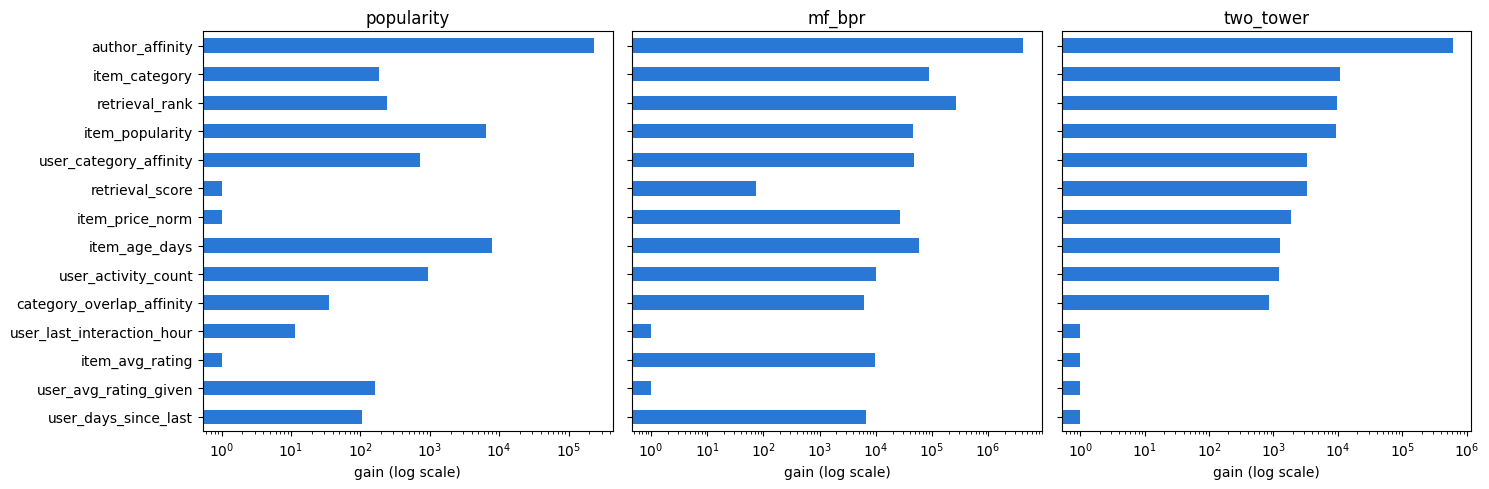


popularity:
author_affinity               231875.262421
item_age_days                   7967.350716
item_popularity                 6477.970575
user_activity_count              946.908998
user_category_affinity           726.150426
retrieval_rank                   238.957463
item_category                    182.501007
user_avg_rating_given            162.335573
user_days_since_last             104.545938
category_overlap_affinity         35.345890
user_last_interaction_hour        11.474300
item_avg_rating                    0.000000
retrieval_score                    0.000000
item_price_norm                    0.000000
dtype: float64

mf_bpr:
author_affinity               4.227642e+06
retrieval_rank                2.710696e+05
item_category                 8.782418e+04
item_age_days                 5.768622e+04
user_category_affinity        4.806329e+04
item_popularity               4.578677e+04
item_price_norm               2.683799e+04
user_activity_count           1.027876e+04
ite

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
feature_order = all_importance["two_tower"].sort_values(ascending=True).index

for ax, name in zip(axes, RETRIEVERS.keys()):
    all_importance[name].reindex(feature_order).clip(lower=1).plot(kind="barh", ax=ax, color="#2a78d6")
    ax.set_title(name)
    ax.set_xlabel("gain (log scale)")
    ax.set_xscale("log")

plt.tight_layout()
plt.show()

for name, imp in all_importance.items():
    print(f"\n{name}:")
    print(imp)

## 14. Summary / notes for `ANALYSIS.md`

**What this notebook delivers.** 14 features across all 4 required groups, and three full retrieval → ranking pipelines (Popularity, MF-BPR, Two-tower), each with its own LightGBM `lambdarank` ranker and its own retrieval-only vs. +LightGBM comparison — a direct, complete answer to project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

**Caveats to carry into `ANALYSIS.md`:**

1. **Two-tower is the strongest retriever across every metric** — NDCG@10, Recall@20/50, and catalog coverage, both before and after ranking. Popularity is weakest across the board, including catalog coverage, since it recommends the same items to everyone. If the team needs to pick a single retriever for production, this run is the evidence.
2. **No impression logs → graded proxy labels.** Amazon Reviews has no "shown but not acted on" signal, so `label∈{0,1,2}` is the closest available proxy — a dataset limitation, not a shortcut we chose.
3. **`author_affinity` dominates feature importance in all three rankers** — the one feature this session added that no other notebook uses. That it holds up regardless of which retriever supplied the candidates is a stronger result than any single run could show on its own.
4. **Early stopping is aggressive for Popularity and MF-BPR** (`best_iteration` in the low single digits) but not for Two-tower — label=2 is under 1% of train rows overall, but Two-tower's more relevant candidate pool gives the model more to learn from before converging.
5. **Columns still dropped** from the raw JSONL: `store`, `rating_number`, `details`, review `text`/`images`/`helpful_vote`/`asin`, product `videos`, `bought_together`, `subtitle`. Only `author` and the full `categories` path were added — the two flagged as highest-value.